# Notebook 07 — Within-Family Consistency (schema-aware)

**Goal:** for each architectural family with ≥2 representatives, verify that the family's members produce internally consistent measurements. If two members of `dual_encoder_contrastive` (CLIP-L vs SigLIP-L vs SigLIP2) give wildly different vision/language param ratios, the extractor or the model selection is broken — and any downstream finding built on family-level averages is suspect.

**Why this notebook exists:** the supervisor's *"within-family generalization"* requirement. A paper claim like *"`adapter_llm` is overwhelmingly language-dominant (mean 96% language)"* is only credible if the 6 family members agree within tens of percent. This notebook computes the agreement explicitly and surfaces any outliers.

**Methodology:**
* For each family with n ≥ 2, compute pair-wise Δ on three metrics: param share per component (V%, F%, L%), FLOPs share per component, V/L ratio.
* Aggregate per family: mean, median, std, coefficient of variation (CV%).
* Flag any family where Δ vision% > 10 percentage points (the supervisor's threshold for inconsistency).

**Inputs:** `../outputs/measurements/master_wide.csv` (built by notebook 06). Falls back to walking the per-model JSONs directly if `master_wide.csv` is missing.

**Outputs:**
* `../outputs/measurements/nb07_within_family.csv` — one row per (family, metric) pair with mean/range/CV.
* `../outputs/measurements/nb07_pairwise.csv` — one row per (family, pair_a, pair_b, metric) with Δ.
* 3 figures in `../outputs/figures/nb07_*.png`.

**Compute:** CPU only. **Runtime:** under 30 seconds.

---
## 1. Setup (Runpod)

In [1]:
# %%capture
# !pip install -q -r ../requirements.txt

In [1]:
import os, sys, json
from pathlib import Path
from itertools import combinations
from collections import defaultdict

NB_DIR = Path.cwd()
CODE_ACTIVE = NB_DIR.parent if NB_DIR.name == 'notebooks' else NB_DIR
sys.path.insert(0, str(CODE_ACTIVE))

MEASUREMENT_DIR = CODE_ACTIVE / 'outputs' / 'measurements'
FIG_DIR = CODE_ACTIVE / 'outputs' / 'figures'
FIG_DIR.mkdir(parents=True, exist_ok=True)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from vlm_audit import MODELS
from vlm_audit.components import COMPONENT_NAMES, EXTENDED_COMPONENT_NAMES

print(f'Working dir:     {NB_DIR}')
print(f'code_active dir: {CODE_ACTIVE}')
print(f'Models in roster: {len(MODELS)}')
print(f'COMPONENT_NAMES:  {COMPONENT_NAMES}')

Working dir:     /workspace/code_active/notebooks
code_active dir: /workspace/code_active
Models in roster: 20
COMPONENT_NAMES:  ('vision', 'fusion', 'language', 'head')


---
## 2. Schema helpers (copied from notebook 02 v3)

Same definitions as in nb02/nb06 so this notebook is self-contained. The within-family analysis uses *schema-aware* aggregation — Chameleon's `fused_transformer` mass counts toward `language_like_M`, and Janus-Pro's two vision pathways are summed into `vision_like_M`.

In [2]:
NATIVE_FUSED_FAMILIES = {'native_early_fusion'}
DECOUPLED_VISION_FAMILIES = {'native_decoupled_encoder'}

def schema_for(family: str) -> str:
    if family in NATIVE_FUSED_FAMILIES:
        return 'native_fused'
    if family in DECOUPLED_VISION_FAMILIES:
        return 'decoupled_vision'
    return 'standard_vflh'

EXTENDED_PARTS = list(EXTENDED_COMPONENT_NAMES)
VISION_LIKE_PARTS = ['vision', 'vision_und', 'vision_gen']
LANGUAGE_LIKE_PARTS = ['language', 'fused_transformer']

def safe_sum(df: pd.DataFrame, parts, suffix: str = '__params_total') -> pd.Series:
    cols = [f'{p}{suffix}' for p in parts if f'{p}{suffix}' in df.columns]
    if not cols:
        return pd.Series([0] * len(df), index=df.index)
    return df[cols].fillna(0).sum(axis=1)

print('schema_for() OK')
print('safe_sum() OK')

schema_for() OK
safe_sum() OK


---
## 3. Load master_wide.csv

If `master_wide.csv` is missing we re-build it inline from per-model JSONs so this notebook still works in isolation. The expected schema is one row per model with `<component>__<metric>` columns over `EXTENDED_COMPONENT_NAMES × {params_total, params_trainable, flops_g, peak_mem_mb, output_tokens, ...}`.

In [3]:
wide_path = MEASUREMENT_DIR / 'master_wide.csv'
if wide_path.exists():
    wide_df = pd.read_csv(wide_path)
    print(f'Loaded master_wide.csv: {len(wide_df)} models, {len(wide_df.columns)} columns')
else:
    print('master_wide.csv missing — re-building inline from per-model JSONs')
    from vlm_audit.schema import ModelRecord
    from vlm_audit.logging_utils import sanitize_for_filename
    rows = []
    for spec in MODELS:
        p = MEASUREMENT_DIR / f'{sanitize_for_filename(spec.hf_id)}.json'
        if not p.exists():
            continue
        with open(p, 'r', encoding='utf-8') as f:
            rec = ModelRecord.from_dict(json.load(f))
        row = {'model_id': rec.model_id, 'name': rec.name or spec.name,
               'family': rec.family or spec.family, 'schema': schema_for(spec.family),
               'release_year': rec.release_year or spec.release_year}
        for part in EXTENDED_PARTS:
            c = rec.components.get(part)
            for m in ['params_total', 'params_trainable', 'flops_g', 'peak_mem_mb', 'output_tokens']:
                row[f'{part}__{m}'] = getattr(c, m, None) if c is not None else None
        rows.append(row)
    wide_df = pd.DataFrame(rows)
    print(f'Re-built wide_df: {len(wide_df)} models, {len(wide_df.columns)} cols (run notebook 06 to persist this)')

# Ensure schema column exists (if loading from existing CSV that lacks it)
if 'schema' not in wide_df.columns:
    wide_df['schema'] = wide_df['family'].apply(schema_for)

wide_df[['name', 'family', 'schema']].head(10)

Loaded master_wide.csv: 20 models, 70 columns


,name,family,schema
0,CLIP-ViT-L/14,dual_encoder_contrastive,standard_vflh
1,SigLIP-L/16,dual_encoder_contrastive,standard_vflh
2,BLIP-large,bridge_module_precursor,standard_vflh
3,BLIP-2-OPT-2.7B,bridge_module,standard_vflh
4,InstructBLIP-Vicuna-7B,bridge_module_adapter_llm,standard_vflh
5,LLaVA-1.5-7B,adapter_llm,standard_vflh
6,LLaVA-NeXT-7B,adapter_llm,standard_vflh
7,IDEFICS-9B,cross_attention_llm,standard_vflh
8,Idefics2-8B,perceiver_adapter_llm,standard_vflh
9,ViLT-B/32,single_stream_fused,standard_vflh


---
## 4. Derive per-model totals and shares

From the wide-format CSV compute, per model:
* `total_params` — schema-aware sum across all components.
* `total_flops_g` — same for FLOPs.
* `vision_pct`, `fusion_pct`, `language_pct` — share of params (vision_like includes both Janus pathways; language_like includes Chameleon's fused body).
* `vision_flops_pct`, `language_flops_pct` — share of FLOPs.
* `v_to_l_ratio` — vision_like / language_like (NaN for native_fused).

These are the metrics the within-family agreement is computed over.

In [4]:
# Make sure expected columns exist (fill missing with 0 so the downstream math works)
for part in EXTENDED_PARTS:
    for m in ['params_total', 'params_trainable', 'flops_g', 'peak_mem_mb', 'output_tokens']:
        c = f'{part}__{m}'
        if c not in wide_df.columns:
            wide_df[c] = np.nan

wide_df['total_params']    = safe_sum(wide_df, EXTENDED_PARTS, '__params_total')
wide_df['total_flops_g']   = safe_sum(wide_df, EXTENDED_PARTS, '__flops_g')
wide_df['total_mem_mb']    = safe_sum(wide_df, EXTENDED_PARTS, '__peak_mem_mb')
wide_df['total_trainable'] = safe_sum(wide_df, EXTENDED_PARTS, '__params_trainable')

vlike = safe_sum(wide_df, VISION_LIKE_PARTS, '__params_total')
llike = safe_sum(wide_df, LANGUAGE_LIKE_PARTS, '__params_total')
fusion = safe_sum(wide_df, ['fusion'], '__params_total')
denom = wide_df['total_params'].clip(lower=1)
wide_df['vision_pct']   = (100 * vlike / denom).round(2)
wide_df['language_pct'] = (100 * llike / denom).round(2)
wide_df['fusion_pct']   = (100 * fusion / denom).round(2)
wide_df['v_to_l_ratio'] = (vlike / llike.replace(0, np.nan)).round(3)

vflops = safe_sum(wide_df, VISION_LIKE_PARTS, '__flops_g')
lflops = safe_sum(wide_df, LANGUAGE_LIKE_PARTS, '__flops_g')
fdenom = wide_df['total_flops_g'].replace(0, np.nan)
wide_df['vision_flops_pct']   = (100 * vflops / fdenom).round(2)
wide_df['language_flops_pct'] = (100 * lflops / fdenom).round(2)

wide_df['trainable_pct'] = (100 * wide_df['total_trainable'] / denom).round(2)

wide_df[['name', 'family', 'schema', 'total_params', 'vision_pct', 'fusion_pct', 'language_pct',
         'v_to_l_ratio', 'vision_flops_pct', 'language_flops_pct', 'trainable_pct']].sort_values(['family', 'name']).reset_index(drop=True)

,name,family,schema,total_params,vision_pct,fusion_pct,language_pct,v_to_l_ratio,vision_flops_pct,language_flops_pct,trainable_pct
0,LLaVA-1.5-7B,adapter_llm,standard_vflh,7.063427e+09,4.30,0.30,93.55,0.046,6.57,93.43,95.70
1,LLaVA-NeXT-7B,adapter_llm,standard_vflh,7.566744e+09,4.01,0.28,93.98,0.043,5.29,94.71,95.99
2,Molmo-7B-D,adapter_llm,standard_vflh,8.021025e+09,5.05,0.00,94.95,0.053,48.90,51.10,94.95
3,Pixtral-12B,adapter_llm_own_encoder,standard_vflh,1.268274e+10,3.18,0.25,91.28,0.035,82.07,17.93,100.00
4,BLIP-2-OPT-2.7B,bridge_module,standard_vflh,3.744737e+09,26.33,2.81,70.81,0.372,27.21,72.78,2.86
5,InstructBLIP-Vicuna-7B,bridge_module_adapter_llm,standard_vflh,7.913702e+09,12.46,2.35,85.16,0.146,10.70,89.30,2.39
6,BLIP-large,bridge_module_precursor,standard_vflh,4.462905e+08,68.05,0.00,31.95,2.130,74.53,25.47,100.00
7,IDEFICS-9B,cross_attention_llm,standard_vflh,7.495160e+09,8.42,1.68,88.15,0.095,43.36,56.60,3.43
8,Llama-3.2-11B-Vision-Instruct,cross_attention_llm,standard_vflh,1.067022e+10,8.09,0.29,86.69,0.093,3.00,97.00,5.22
9,CLIP-ViT-L/14,dual_encoder_contrastive,standard_vflh,4.276165e+08,70.90,0.32,28.78,2.464,93.47,6.53,100.00


---
## 5. Family roster (who belongs where)

Print the family → members map before doing pair-wise math. Families with n=1 will be excluded from the pair-wise table (no pair to compare) but kept in the per-family summary so single-member families don't silently disappear.

In [5]:
family_members = wide_df.groupby('family')['name'].apply(list).to_dict()
n_per_family = {fam: len(members) for fam, members in family_members.items()}
print(f'{"FAMILY":40s}  N  MEMBERS')
print('-' * 110)
for fam in sorted(family_members):
    members = family_members[fam]
    n = len(members)
    star = '★' if n >= 2 else ' '
    print(f'{star} {fam:38s} {n:>2d}  {", ".join(members)}')
print(f'\nFamilies eligible for pair-wise: {sum(1 for n in n_per_family.values() if n >= 2)}')
print(f'Families with n=1 (excluded from pairs):  {sum(1 for n in n_per_family.values() if n == 1)}')

FAMILY                                    N  MEMBERS
--------------------------------------------------------------------------------------------------------------
★ adapter_llm                             3  LLaVA-1.5-7B, LLaVA-NeXT-7B, Molmo-7B-D
  adapter_llm_own_encoder                 1  Pixtral-12B
  bridge_module                           1  BLIP-2-OPT-2.7B
  bridge_module_adapter_llm               1  InstructBLIP-Vicuna-7B
  bridge_module_precursor                 1  BLIP-large
★ cross_attention_llm                     2  IDEFICS-9B, Llama-3.2-11B-Vision-Instruct
★ dual_encoder_contrastive                3  CLIP-ViT-L/14, SigLIP-L/16, SigLIP2-So400m/14
★ dynamic_tile_adapter_llm                3  Qwen2-VL-7B-Instruct, Qwen2.5-VL-7B-Instruct, InternVL3-8B
  moe_adapter_llm                         1  DeepSeek-VL2-Small
  native_decoupled_encoder                1  Janus-Pro-7B
  native_early_fusion                     1  Chameleon-7B
  perceiver_adapter_llm                   1  Id

---
## 6. Pair-wise within-family differences

For each family with n ≥ 2 and each unordered pair (a, b), compute the absolute and percent difference on each metric. Percent difference uses the pair-average as denominator (so it's symmetric in a/b).

Six metrics per pair:
* `params` — total params
* `flops_g` — total FLOPs
* `peak_mem_mb` — total peak memory
* `vision_pct` — vision share of params (in percentage **points**, not relative %)
* `language_pct` — language share of params (percentage points)
* `v_to_l_ratio` — vision/language param ratio

In [6]:
PAIR_METRICS = [
    ('total_params',     'params',       'rel'),     # use pair-avg denominator
    ('total_flops_g',    'flops_g',      'rel'),
    ('total_mem_mb',     'peak_mem_mb',  'rel'),
    ('vision_pct',       'vision_pct',   'abs'),     # difference in percentage points
    ('language_pct',     'language_pct', 'abs'),
    ('v_to_l_ratio',     'v_to_l_ratio', 'rel'),
]

pair_rows = []
for fam, group in wide_df.groupby('family'):
    if len(group) < 2:
        continue
    members = group.reset_index(drop=True)
    for i, j in combinations(range(len(members)), 2):
        a, b = members.iloc[i], members.iloc[j]
        for col, label, mode in PAIR_METRICS:
            a_val = a[col]
            b_val = b[col]
            if pd.isna(a_val) and pd.isna(b_val):
                continue
            a_val = 0 if pd.isna(a_val) else a_val
            b_val = 0 if pd.isna(b_val) else b_val
            abs_diff = abs(b_val - a_val)
            if mode == 'rel':
                avg = (a_val + b_val) / 2 if (a_val and b_val) else max(a_val, b_val)
                pct = (100 * (b_val - a_val) / avg) if avg else None
            else:
                pct = b_val - a_val  # already in percentage points
            pair_rows.append({
                'family':         fam,
                'metric':         label,
                'mode':           mode,
                'model_a':        a['name'],
                'model_b':        b['name'],
                'a_value':        a_val,
                'b_value':        b_val,
                'abs_diff':       abs_diff,
                'pct_diff_or_pp': round(pct, 2) if pct is not None else None,
            })

pair_df = pd.DataFrame(pair_rows)
print(f'Built {len(pair_df)} pair-wise rows across {pair_df["family"].nunique()} families')
pair_df.sort_values(['family', 'metric']).reset_index(drop=True)

Built 60 pair-wise rows across 4 families


,family,metric,mode,model_a,model_b,a_value,b_value,abs_diff,pct_diff_or_pp
0,adapter_llm,flops_g,rel,LLaVA-1.5-7B,LLaVA-NeXT-7B,5.323221e+03,6.603221e+03,1.280000e+03,21.46
1,adapter_llm,flops_g,rel,LLaVA-1.5-7B,Molmo-7B-D,5.323221e+03,9.539312e+02,4.369290e+03,-139.21
2,adapter_llm,flops_g,rel,LLaVA-NeXT-7B,Molmo-7B-D,6.603221e+03,9.539312e+02,5.649290e+03,-149.51
3,adapter_llm,language_pct,abs,LLaVA-1.5-7B,LLaVA-NeXT-7B,9.355000e+01,9.398000e+01,4.300000e-01,0.43
4,adapter_llm,language_pct,abs,LLaVA-1.5-7B,Molmo-7B-D,9.355000e+01,9.495000e+01,1.400000e+00,1.40
5,adapter_llm,language_pct,abs,LLaVA-NeXT-7B,Molmo-7B-D,9.398000e+01,9.495000e+01,9.700000e-01,0.97
6,adapter_llm,params,rel,LLaVA-1.5-7B,LLaVA-NeXT-7B,7.063427e+09,7.566744e+09,5.033165e+08,6.88
7,adapter_llm,params,rel,LLaVA-1.5-7B,Molmo-7B-D,7.063427e+09,8.021025e+09,9.575982e+08,12.70
8,adapter_llm,params,rel,LLaVA-NeXT-7B,Molmo-7B-D,7.566744e+09,8.021025e+09,4.542817e+08,5.83
9,adapter_llm,peak_mem_mb,rel,LLaVA-1.5-7B,LLaVA-NeXT-7B,1.383335e+04,1.476996e+04,9.366094e+02,6.55


---
## 7. Per-family consistency table

Aggregate the pair-wise rows back up to one row per (family, metric): mean & max of |Δ|. Also compute the **coefficient of variation** (CV%) across all family members for each metric — a complementary signal that doesn't need pairing and is well-defined for families of any size.

**Flag** families whose mean |Δvision%| or |Δlanguage%| exceeds 10 percentage points — that's the supervisor's threshold for "family is internally inconsistent; re-check extractor".

In [7]:
FLAG_PP_THRESHOLD = 10  # percentage points
FLAG_REL_THRESHOLD = 50  # percent

summary_rows = []
if not pair_df.empty:
    for (fam, metric), g in pair_df.groupby(['family', 'metric']):
        mode = g['mode'].iloc[0]
        mean_abs = g['pct_diff_or_pp'].abs().mean()
        max_abs = g['pct_diff_or_pp'].abs().max()
        thresh = FLAG_PP_THRESHOLD if mode == 'abs' else FLAG_REL_THRESHOLD
        flag = '⚠ inconsistent' if mean_abs > thresh else '✓ consistent'
        summary_rows.append({
            'family': fam,
            'metric': metric,
            'mode': mode,
            'n_pairs': len(g),
            'mean_abs_diff': round(mean_abs, 2),
            'max_abs_diff': round(max_abs, 2),
            'threshold': thresh,
            'flag': flag,
        })

# Also compute CV% across family members on the raw metrics (works for n=1 too — CV = 0)
CV_METRICS = [('total_params', 'params'), ('total_flops_g', 'flops_g'),
              ('vision_pct', 'vision_pct'), ('language_pct', 'language_pct'),
              ('v_to_l_ratio', 'v_to_l_ratio')]
cv_rows = []
for fam, group in wide_df.groupby('family'):
    for col, label in CV_METRICS:
        vals = group[col].dropna().values
        if len(vals) == 0:
            continue
        mean = float(np.mean(vals))
        std = float(np.std(vals)) if len(vals) > 1 else 0.0
        cv = (100 * std / mean) if mean != 0 else 0.0
        cv_rows.append({
            'family': fam,
            'metric': label,
            'n_members': len(vals),
            'mean': round(mean, 4),
            'std': round(std, 4),
            'cv_pct': round(cv, 2),
            'min': round(float(np.min(vals)), 4),
            'max': round(float(np.max(vals)), 4),
        })
cv_df = pd.DataFrame(cv_rows)
summary_df = pd.DataFrame(summary_rows)
print(f'Per-family pair-wise summary: {len(summary_df)} rows')
print(f'Per-family CV summary:        {len(cv_df)} rows')
summary_df.sort_values(['flag', 'family', 'metric']).reset_index(drop=True) if not summary_df.empty else None

Per-family pair-wise summary: 24 rows
Per-family CV summary:        65 rows


,family,metric,mode,n_pairs,mean_abs_diff,max_abs_diff,threshold,flag
0,adapter_llm,flops_g,rel,3,103.39,149.51,50,⚠ inconsistent
1,adapter_llm,peak_mem_mb,rel,3,68.85,100.00,50,⚠ inconsistent
2,cross_attention_llm,flops_g,rel,1,180.70,180.70,50,⚠ inconsistent
3,cross_attention_llm,peak_mem_mb,rel,1,176.24,176.24,50,⚠ inconsistent
4,dual_encoder_contrastive,flops_g,rel,3,86.49,128.48,50,⚠ inconsistent
5,dual_encoder_contrastive,language_pct,abs,3,22.35,33.52,10,⚠ inconsistent
6,dual_encoder_contrastive,params,rel,3,62.11,90.61,50,⚠ inconsistent
7,dual_encoder_contrastive,v_to_l_ratio,rel,3,84.69,121.15,50,⚠ inconsistent
8,dual_encoder_contrastive,vision_pct,abs,3,22.13,33.20,10,⚠ inconsistent
9,dynamic_tile_adapter_llm,v_to_l_ratio,rel,3,54.90,82.35,50,⚠ inconsistent


In [8]:
# Flag summary
if summary_df.empty:
    print('No pair-wise comparisons possible (every family has n=1)')
else:
    flagged = summary_df[summary_df['flag'].str.startswith('⚠')]
    if flagged.empty:
        print(f'✓ All {summary_df["family"].nunique()} multi-member families pass consistency checks.')
    else:
        print(f'⚠ {len(flagged)} (family, metric) cells exceed threshold:')
        for _, r in flagged.iterrows():
            print(f'  - {r["family"]:38s} {r["metric"]:14s} mean_abs_diff={r["mean_abs_diff"]:.2f} > {r["threshold"]} ({r["mode"]})')
        print('\nInvestigate the offending pair in the pair-wise table and decide:')
        print('  - extractor bug (run vlm_audit/components.py on the model in isolation)')
        print('  - genuine within-family heterogeneity (note in paper; family is not monolithic)')
        print('  - model selection issue (one of the family members is not really in the family)')

⚠ 10 (family, metric) cells exceed threshold:
  - adapter_llm                            flops_g        mean_abs_diff=103.39 > 50 (rel)
  - adapter_llm                            peak_mem_mb    mean_abs_diff=68.85 > 50 (rel)
  - cross_attention_llm                    flops_g        mean_abs_diff=180.70 > 50 (rel)
  - cross_attention_llm                    peak_mem_mb    mean_abs_diff=176.24 > 50 (rel)
  - dual_encoder_contrastive               flops_g        mean_abs_diff=86.49 > 50 (rel)
  - dual_encoder_contrastive               language_pct   mean_abs_diff=22.35 > 10 (abs)
  - dual_encoder_contrastive               params         mean_abs_diff=62.11 > 50 (rel)
  - dual_encoder_contrastive               v_to_l_ratio   mean_abs_diff=84.69 > 50 (rel)
  - dual_encoder_contrastive               vision_pct     mean_abs_diff=22.13 > 10 (abs)
  - dynamic_tile_adapter_llm               v_to_l_ratio   mean_abs_diff=54.90 > 50 (rel)

Investigate the offending pair in the pair-wise table and de

---
## 8. CV table (per-family coefficient of variation)

Complementary view to §7. CV% = std / mean × 100. Low CV% means family members are tight (interchangeable); high CV% means they're spread out.

**Expectations:**
* `adapter_llm` (LLaVA-1.5, LLaVA-NeXT, Molmo, IDEFICS, Idefics2) should have low CV on `language_pct` (all ~95%+) but possibly high CV on `total_params` (different LLM sizes).
* `dual_encoder_contrastive` (CLIP, SigLIP, SigLIP2) should have low CV on `vision_pct` (all ~55-70%) and `v_to_l_ratio`.
* Single-member families (`perceiver_adapter_llm`, native families) show CV=0 trivially.

In [9]:
if cv_df.empty:
    print('No CV rows computed.')
else:
    # Pivot to a (family × metric) view for compactness
    cv_pivot = cv_df.pivot_table(index='family', columns='metric', values='cv_pct', fill_value=np.nan)
    cv_pivot

---
## 9. Figure 1 — vision% violin/swarm by family

One y-axis tick per family. For each family plot every member as a dot at its `vision_pct`. Lets you eyeball both family location (~where the dots cluster) and spread (how tight the dot cloud is). This is the headline within-family figure for the paper supplement.

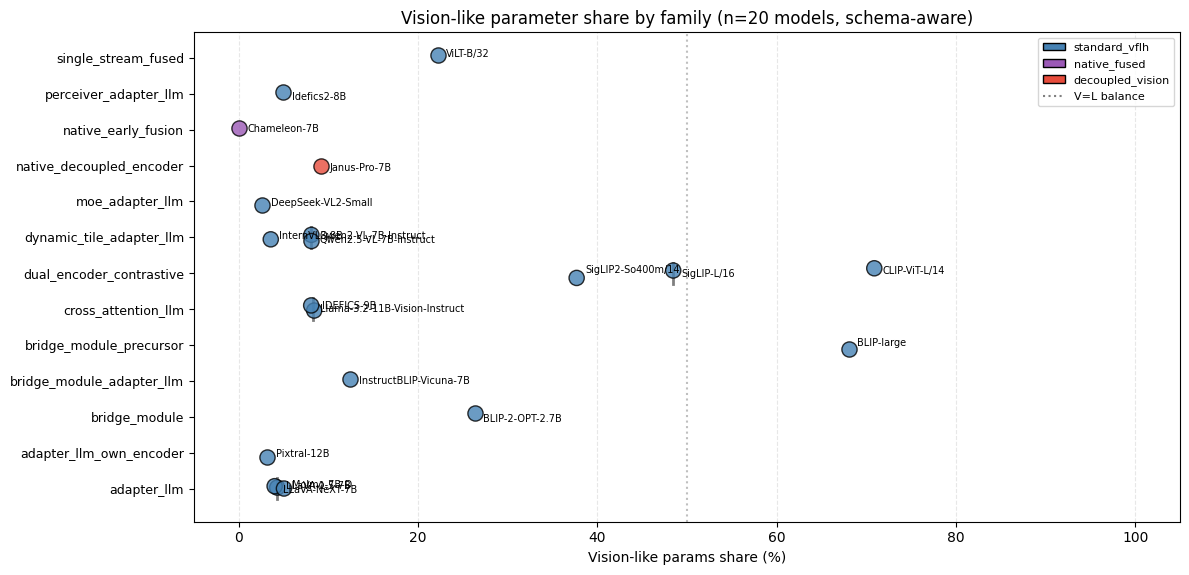

Saved /workspace/code_active/outputs/figures/nb07_vision_pct_by_family.png


In [10]:
fig, ax = plt.subplots(figsize=(12, max(5, 0.45 * wide_df['family'].nunique())))
families = sorted(wide_df['family'].unique())
y_positions = {fam: i for i, fam in enumerate(families)}

# Color by schema
schema_colors = {'standard_vflh': 'steelblue', 'native_fused': '#9B59B6', 'decoupled_vision': '#E74C3C'}

for fam in families:
    sub = wide_df[wide_df['family'] == fam]
    ys = [y_positions[fam] + np.random.uniform(-0.15, 0.15) for _ in range(len(sub))]  # jitter
    colors = [schema_colors.get(s, 'gray') for s in sub['schema']]
    ax.scatter(sub['vision_pct'], ys, c=colors, s=120, edgecolor='black', alpha=0.8, zorder=3)
    for _, r in sub.iterrows():
        y_jit = y_positions[fam] + np.random.uniform(-0.1, 0.1)
        ax.annotate(r['name'], (r['vision_pct'], y_jit), xytext=(6, 0),
                    textcoords='offset points', fontsize=7, va='center')
    # Median line for visual reference
    if len(sub) >= 2:
        med = sub['vision_pct'].median()
        ax.plot([med, med], [y_positions[fam] - 0.3, y_positions[fam] + 0.3], 'k-', linewidth=2, alpha=0.5, zorder=2)

ax.set_yticks(list(y_positions.values()))
ax.set_yticklabels(list(y_positions.keys()), fontsize=9)
ax.set_xlabel('Vision-like params share (%)')
ax.set_xlim(-5, 105)
ax.axvline(50, color='gray', linestyle=':', alpha=0.5, label='V = L balance')
ax.set_title(f'Vision-like parameter share by family (n={len(wide_df)} models, schema-aware)')
ax.grid(True, axis='x', linestyle='--', alpha=0.3)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(facecolor=c, label=s, edgecolor='black') for s, c in schema_colors.items()] + [plt.Line2D([], [], color='gray', linestyle=':', label='V=L balance')],
          loc='upper right', fontsize=8)
plt.tight_layout()
plt.savefig(FIG_DIR / 'nb07_vision_pct_by_family.png', dpi=300, bbox_inches='tight')
plt.show()
print(f'Saved {FIG_DIR / "nb07_vision_pct_by_family.png"}')

---
## 10. Figure 2 — V/L ratio × release year (do families drift over time?)

X = release year, Y = V/L ratio (log), color = family. Looking for trajectory: does any family consistently move toward L-dominance (or balance) as time passes? Useful for the paper's *generational evolution* narrative (and feeds notebook 14).

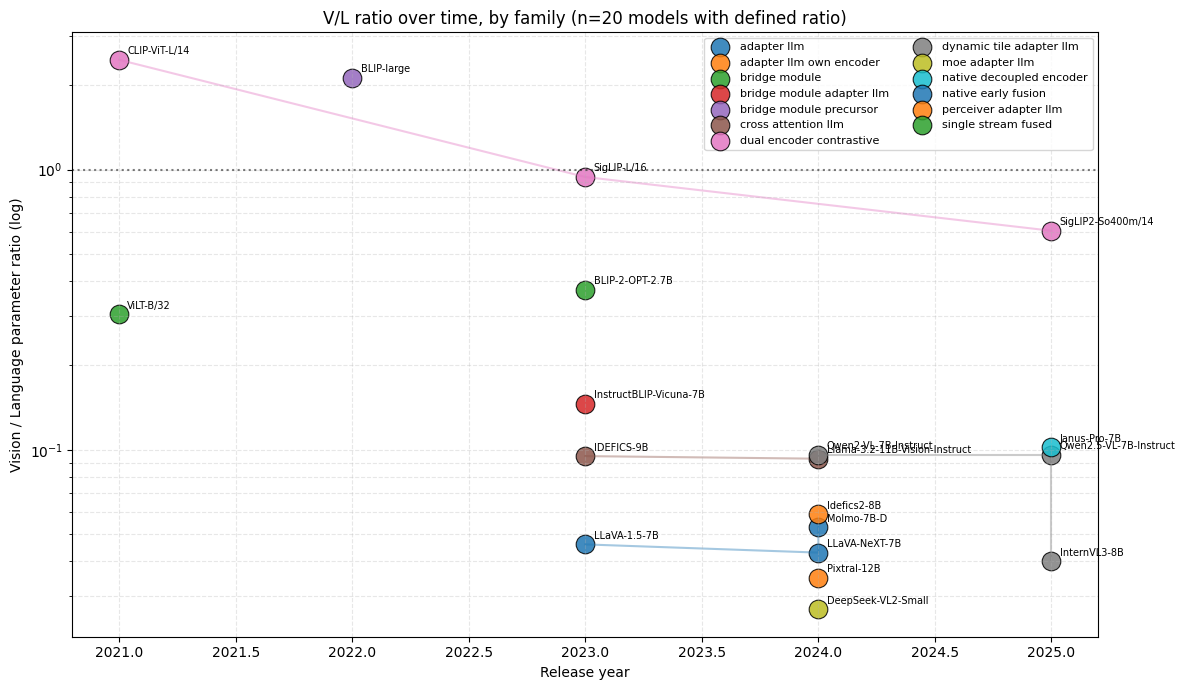

Saved /workspace/code_active/outputs/figures/nb07_vl_ratio_by_year.png


In [11]:
fig, ax = plt.subplots(figsize=(12, 7))
families = sorted(wide_df['family'].unique())
cmap = plt.get_cmap('tab10')
fam_color = {fam: cmap(i % 10) for i, fam in enumerate(families)}
for fam in families:
    sub = wide_df[wide_df['family'] == fam].dropna(subset=['v_to_l_ratio'])
    if sub.empty:
        continue
    ax.scatter(sub['release_year'], sub['v_to_l_ratio'], color=fam_color[fam],
               s=180, edgecolor='black', linewidth=0.8, alpha=0.85, label=fam.replace('_', ' '))
    for _, r in sub.iterrows():
        ax.annotate(r['name'], (r['release_year'], r['v_to_l_ratio']),
                    xytext=(6, 4), textcoords='offset points', fontsize=7)
    # Connect within-family points by year
    if len(sub) >= 2:
        s2 = sub.sort_values('release_year')
        ax.plot(s2['release_year'], s2['v_to_l_ratio'], color=fam_color[fam], alpha=0.4, linewidth=1.5, zorder=1)

ax.set_yscale('log')
ax.axhline(1.0, color='black', linestyle=':', alpha=0.5)
ax.set_xlabel('Release year')
ax.set_ylabel('Vision / Language parameter ratio (log)')
ax.set_title(f'V/L ratio over time, by family (n={wide_df["v_to_l_ratio"].notna().sum()} models with defined ratio)')
ax.grid(True, which='both', linestyle='--', alpha=0.3)
ax.legend(loc='upper right', fontsize=8, ncol=2)
plt.tight_layout()
plt.savefig(FIG_DIR / 'nb07_vl_ratio_by_year.png', dpi=300, bbox_inches='tight')
plt.show()
print(f'Saved {FIG_DIR / "nb07_vl_ratio_by_year.png"}')

---
## 11. Figure 3 — coefficient of variation bar (per family, per metric)

Side-by-side bars: for each family show CV% on `total_params`, `vision_pct`, `language_pct`. Tighter bars mean a more homogeneous family. Useful for spotting which family is the most internally consistent and which is the most heterogeneous.

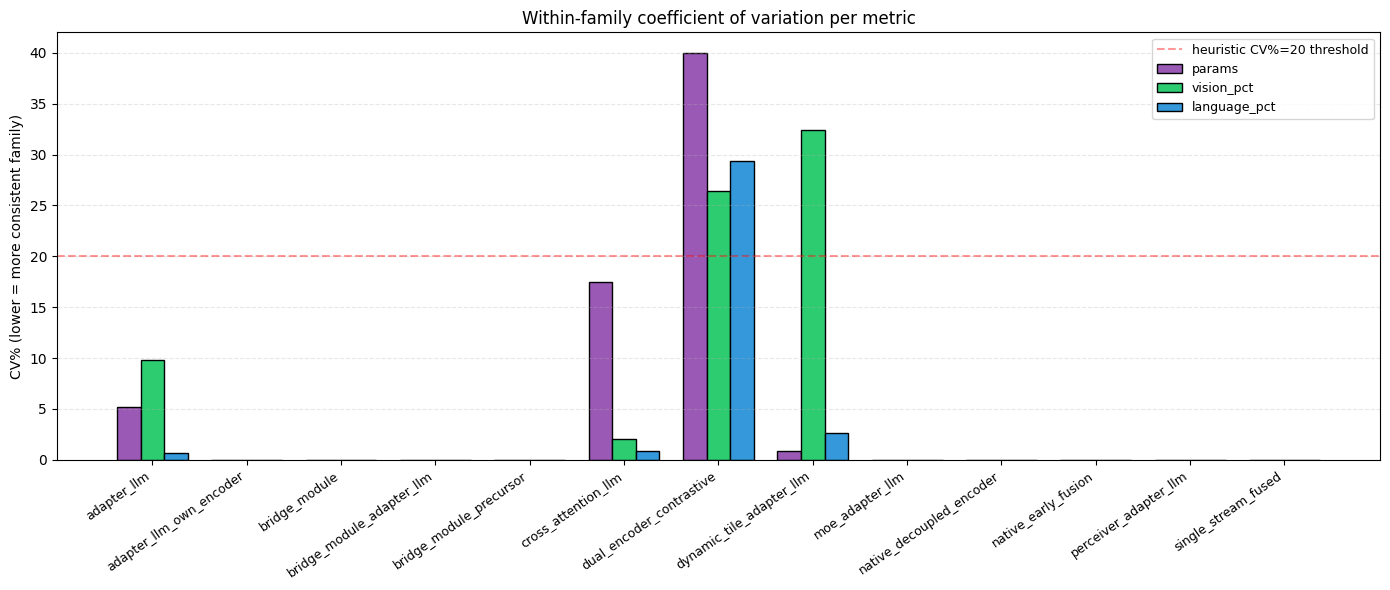

Saved /workspace/code_active/outputs/figures/nb07_cv_by_family.png


In [12]:
if cv_df.empty:
    print('No CV data; skipping figure 3.')
else:
    metrics_for_plot = ['params', 'vision_pct', 'language_pct']
    metric_colors = {'params': '#9B59B6', 'vision_pct': '#2ECC71', 'language_pct': '#3498DB'}
    families = sorted(cv_df['family'].unique())
    x = np.arange(len(families))
    width = 0.25

    fig, ax = plt.subplots(figsize=(14, 6))
    for i, m in enumerate(metrics_for_plot):
        sub = cv_df[cv_df['metric'] == m].set_index('family')
        vals = [sub['cv_pct'].get(fam, 0) for fam in families]
        ax.bar(x + (i - 1) * width, vals, width=width, color=metric_colors[m], edgecolor='black', label=m)
    ax.set_xticks(x)
    ax.set_xticklabels(families, rotation=35, ha='right', fontsize=9)
    ax.set_ylabel('CV% (lower = more consistent family)')
    ax.set_title('Within-family coefficient of variation per metric')
    ax.axhline(20, color='red', linestyle='--', alpha=0.4, label='heuristic CV%=20 threshold')
    ax.legend(loc='upper right', fontsize=9)
    ax.grid(True, axis='y', linestyle='--', alpha=0.3)
    plt.tight_layout()
    plt.savefig(FIG_DIR / 'nb07_cv_by_family.png', dpi=300, bbox_inches='tight')
    plt.show()
    print(f'Saved {FIG_DIR / "nb07_cv_by_family.png"}')

---
## 12. Interpretation

**Expected patterns (write the paper around these):**

* **`adapter_llm` family** (LLaVA-1.5, LLaVA-NeXT, Molmo, +adjacent): low CV on `language_pct` (all ~94-97%) — the family is overwhelmingly homogeneous on the language-dominance signal. CV on `total_params` may be higher because different members ship different LLM sizes (7B vs 13B etc.).
* **`dual_encoder_contrastive`** (CLIP, SigLIP, SigLIP2): low CV on `vision_pct` and `v_to_l_ratio`. Vision-dominant pattern is the family's defining trait and it's stable.
* **`bridge_module*` families**: medium CV — different bridge architectures (Q-Former vs cross-attention) move the fusion share around, but the vision and language shares stay similar.
* **`single_stream_fused`** (ViLT, n=1): no within-family variance; trivially "consistent".
* **Native families** (`native_early_fusion`=Chameleon, `native_decoupled_encoder`=Janus-Pro): n=1 each → CV=0 by construction. These don't contribute to the within-family validation argument.
* **`perceiver_adapter_llm`** (Idefics2-only): n=1 → flagged as "insufficient evidence" in the paper if we keep it as its own family. Consider merging with `adapter_llm` or `cross_attention_llm` for the analysis.

Any pattern that doesn't match the expectations above is a finding in itself — note it for the discussion section.

---
## 13. Save outputs

In [13]:
out_pairs = MEASUREMENT_DIR / 'nb07_pairwise.csv'
out_summary = MEASUREMENT_DIR / 'nb07_within_family.csv'
out_cv = MEASUREMENT_DIR / 'nb07_cv.csv'

if not pair_df.empty:
    pair_df.to_csv(out_pairs, index=False)
    print(f'Wrote: {out_pairs}  ({len(pair_df)} rows)')
else:
    print('Pair-wise table empty — skipping nb07_pairwise.csv')

if not summary_df.empty:
    summary_df.to_csv(out_summary, index=False)
    print(f'Wrote: {out_summary}  ({len(summary_df)} rows)')
else:
    print('Summary table empty — skipping nb07_within_family.csv')

if not cv_df.empty:
    cv_df.to_csv(out_cv, index=False)
    print(f'Wrote: {out_cv}  ({len(cv_df)} rows)')

Wrote: /workspace/code_active/outputs/measurements/nb07_pairwise.csv  (60 rows)
Wrote: /workspace/code_active/outputs/measurements/nb07_within_family.csv  (24 rows)
Wrote: /workspace/code_active/outputs/measurements/nb07_cv.csv  (65 rows)


---
## Next steps

* Open **`08_findings_F1_to_F10.ipynb`** — the headline analysis notebook. The within-family CV table from this notebook will be referenced by F1 ("the asymmetry pattern persists across families") and F8 ("family clustering is real, not artifact").
* If any family failed §7's threshold check, fix the extractor or pull the bad model before continuing — F1 / F2 / F8 will all inherit the bad data.

*End of notebook 07 (v3 — 2026-05-22).*